# Recommendation Systems

Recommender systems are at the core of pretty much every online service we interact with. Social networking sites like Facebook, Twitter and Instagram recommend posts you might like, or people you might know. Video streaming services like YouTube and Netflix recommend videos, movies or TV shows you might like. Online shopping sites like Amazon recommend products you might want to buy. 

**Collaborative** filtering is perhaps the most common technique used by recommender systems.

> *Collaborative filtering is a method of making predictions about the interests of a user by collecting preferences from many users. The underlying assumption is that if a person A has the same opinion as a person B on an issue, A is more likely to have B's opinion on a different issue than that of a randomly chosen person.*

The [librec](https://medium.com/r/?url=https%3A%2F%2Fwww.librec.net%2F) Java library provides [over 70 different algorithms](https://medium.com/r/?url=https%3A%2F%2Fwww.librec.net%2Fdokuwiki%2Fdoku.php%3Fid%3DAlgorithmList%23recommender_algorithm_list) for collaborative filtering. In this post however, we'll implement a relatively new technique called *neural collaborative filtering*.

## The MovieLens 100K Dataset

The [MovieLens 100K dataset](https://grouplens.org/datasets/movielens/) is a collection of movie ratings by 943 users on 1682 movies. There are 100,000 ratings in total, since not every user has seen and rated every movie. Here are some sample ratings from the dataset:

<img src="https://cdn-images-1.medium.com/max/800/1*OZLI7a0ueujHzj5NG3oRlQ.png" style="width:360px" />

Every user is given a unique numeric ID (ranging from 1 to 943), and each movie is given a unique numeric ID too (ranging from 1 to 1682). User's ratings for movies are integers ranging from 1 to 5, with 5 being the highest.

Our objective here is to build a *model* that can predict how a user would rate a movie they haven't already seen, by looking at the movie ratings of other users with similar tastes.

We begin the importing the required modules from Pandas and FastAI.

In [1]:
import pandas as pd
from fastai.collab import CollabDataLoaders, collab_learner

C:\Users\God -01.11\Desktop\AI Course\5-Machine Learning wiht Scikit Learn\Machine-Learning-with-Scikit-Learn\.venv\Lib\site-packages\torch\jit\_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


We can now read the data from the CSV file `u.data` into a Pandas [data frame](https://medium.com/r/?url=https%3A%2F%2Fpandas.pydata.org%2Fpandas-docs%2Fstable%2Freference%2Fapi%2Fpandas.DataFrame.html), and create a FastAI [data bunch](https://medium.com/r/?url=https%3A%2F%2Fdocs.fast.ai%2Fbasic_data.html%23Get-your-data-ready-for-training) which:

1. Converts the Pandas data frame into tensors
2. It splits the data into a training set and a validation set
3. Creates data loaders to access the data in batches
4. Checks if a GPU is available, and moves the data to the GPU

In [2]:
cols = ['User ID','Movie ID','Rating','Timestamp']
ratings_df = pd.read_csv('ml-100k/u.data', delimiter='\t', 
                         header=None, names=cols)
ratings_df.sample(5)

,User ID,Movie ID,Rating,Timestamp
48274,597,295,3,875340117
19045,222,222,4,877563462
3309,291,824,4,874833962
40082,399,215,2,882510226
66839,909,582,5,891920125


In [3]:
data = CollabDataLoaders.from_df(ratings_df, user_name='User ID', item_name='Movie ID',
                                 rating_name='Rating', valid_pct=0.1)
data.show_batch()

C:\Users\God -01.11\Desktop\AI Course\5-Machine Learning wiht Scikit Learn\Machine-Learning-with-Scikit-Learn\.venv\Lib\site-packages\fastai\torch_core.py:155: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  else as_tensor(x.values, **kwargs) if isinstance(x, (pd.Series, pd.DataFrame))


,User ID,Movie ID,Rating
0,399,633,3
1,851,92,5
2,828,270,5
3,387,317,4
4,793,1142,5
5,308,487,4
6,158,183,3
7,927,38,5
8,286,154,4
9,459,1115,3


## Neural collaborative filtering model

The model itself is quite simple. We represent each user `u` and each movie `m` by vector of a predefined length `n`. The rating for the movie `m` by the user `u`, as predicted by the model is simply the dot product of the two vectors.

<img src="https://cdn-images-1.medium.com/max/800/1*RuAjbXDwvTAv74NtPS-FbQ.png" style="width:360px"/>

Here's a small subset of the users and movies, represented by randomly chosen vectors of length 5, and the predicted ratings:

<img src="https://cdn-images-1.medium.com/max/1600/1*y9H2v3PsytrCajWSNJJDsA.png" style="width:480px"/>

Since the vectors are chosen randomly, it's quite unlikely that the ratings predicted by the model match the actual ratings. Our objective, while training the model, is to gradually adjust the elements inside the user & movie vectors so that predicted ratings get closer to the actual ratings.

We can use the `collab_learner` method from `fastai` to create a neural collaborative filtering model.

In [5]:
learn = collab_learner(data, n_factors=40, y_range=(0, 5.5), wd=.1)

The actual model created here contains 2 important enhancements on the simpler version described earlier:

First, apart from the vectors for users and movies, it also add bias terms to account for outliers, since some users tend to always rate movies very high or very low, and some movies tend to be universally acclaimed or disliked.

<img src="https://cdn-images-1.medium.com/max/800/1*vF7oEwpuKfXP8_CYK_KgdQ.png" style="width:360px" />

Second, it applies the Sigmoid activation function to the above output, and scales it so that the result always lies in the given `y_range`, which is 0 to 5.5 in this case.

<img src="https://cdn-images-1.medium.com/max/800/1*NloTSPs4pCMYDZ8G1kxhoQ.png" style="width:420px"/>

## Training the model

The learner uses the [*mean squared error*](https://en.wikipedia.org/wiki/Mean_squared_error) loss function to evaluate the predictions of the model, and the [Adam optimizer](https://machinelearningmastery.com/adam-optimization-algorithm-for-deep-learning/) to adjust the parameters (vectors and biases) using gradient descent. Before we train the model, we use the [learning rate finder](https://docs.fast.ai/callbacks.lr_finder.html) to select a good learning for the optimizer.

<div></div>

SuggestedLRs(valley=0.013182567432522774)

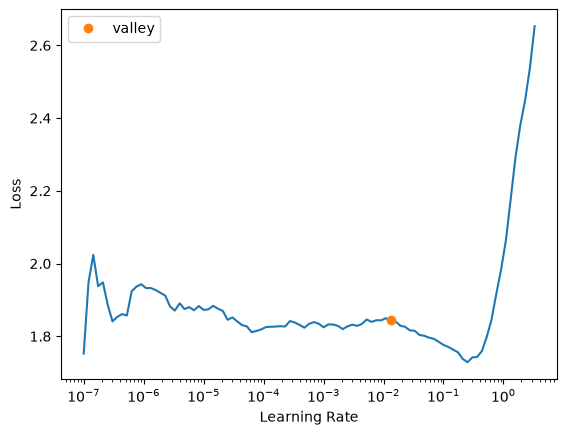

In [6]:
learn.lr_find()

Upon inspection of the graph, we can see that the decrease in loss starts to decrease when the learning rate is around `0.01`. We can choose this as our learning rate, and train for 5 epochs, while annealing the learning rate using the [1-cycle policy](https://sgugger.github.io/the-1cycle-policy.html), which leads to faster convergence.

In [7]:
learn.fit_one_cycle(5, 0.01)

epoch,train_loss,valid_loss,time
0,0.849183,0.976692,00:11
1,0.670840,0.931621,00:11
2,0.553432,0.899112,00:13
3,0.463536,0.864622,00:12
4,0.449035,0.857039,00:11


In few seconds, the mean squared error has come down to around 0.82. And it only took us 8 lines of code to load the data and train the model!

## Looking at some predictions

While it's great to see the loss go down, let's look at some actual predictions of the model.

In [9]:
import torch

x, ratings = data.valid.one_batch()
with torch.no_grad():
    preds = learn.model(x)

titles = pd.read_csv('ml-100k/u.item', sep='|', encoding='latin-1', header=None,
                     usecols=[0, 1], names=['Movie ID', 'Title']).set_index('Movie ID')['Title']

results = pd.DataFrame({
    'User': [data.classes['User ID'][i] for i in x[:, 0].tolist()],
    'Movie': [titles.get(data.classes['Movie ID'][i], '(unseen in training)') for i in x[:, 1].tolist()],
    'Real': ratings.flatten().tolist(),
    'Predicted': preds.flatten().tolist(),
})
results['Difference'] = results['Predicted'] - results['Real']

(results.head(16).style
    .format({'Real': '{:.0f}', 'Predicted': '{:.1f}', 'Difference': '{:+.1f}'})
    .bar(subset=['Difference'], align='zero', color=['#d65f5f', '#5fba7d'], vmin=-2, vmax=2)
    .set_properties(subset=['Movie'], **{'text-align': 'left'})
    .hide(axis='index'))

User,Movie,Real,Predicted,Difference
782,Night Flier (1997),3,2.8,-0.2
16,"Sound of Music, The (1965)",5,4.3,-0.7
426,Monty Python and the Holy Grail (1974),3,3.9,+0.9
790,How to Make an American Quilt (1995),4,2.6,-1.4
842,"Apostle, The (1997)",1,3.9,+2.9
193,Butch Cassidy and the Sundance Kid (1969),4,4.1,+0.1
455,"Family Thing, A (1996)",4,3.3,-0.7
867,Hamlet (1996),5,4.5,-0.5
702,Rocket Man (1997),1,1.4,+0.4
279,Mother (1996),5,2.4,-2.6


Indeed, the predictions are quite close to the actual ratings. We can now use this model to predict how users would rate movies they haven't seen, and recommend movies that have a high predicted rating.

<img src="https://cdn-images-1.medium.com/max/800/1*YXlBhnk7cQw5cjbW9qBm0A.png" style="max-width:480px" />